<a href="https://colab.research.google.com/github/Salalahmdi/Advanced-Statistics-Transportation/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   section_id  survey_year route_id road_class region climate_zone  \
0       10001         2018      R39  Collector  Rural    Semi-Arid   
1       10001         2019      R15  Collector  Rural    Semi-Arid   
2       10001         2020      R29  Collector  Rural    Semi-Arid   
3       10001         2021      R21  Collector  Rural    Semi-Arid   
4       10001         2022      R02  Collector  Rural    Semi-Arid   

  pavement_type     surface_type  lanes  length  ...  IRI_m_per_km  \
0      Flexible  Dense-Graded AC      2   11.33  ...          3.12   
1      Flexible  Dense-Graded AC      2   11.33  ...          3.48   
2      Flexible  Dense-Graded AC      2   11.33  ...          4.07   
3      Flexible  Dense-Graded AC      2   11.33  ...          3.51   
4      Flexible  Dense-Graded AC      2   11.33  ...          3.55   

   rut_depth_mm  cracking_percent  FWD_deflection_mm  skid_resistance  \
0          3.98             10.20              0.280            52.12   
1          3

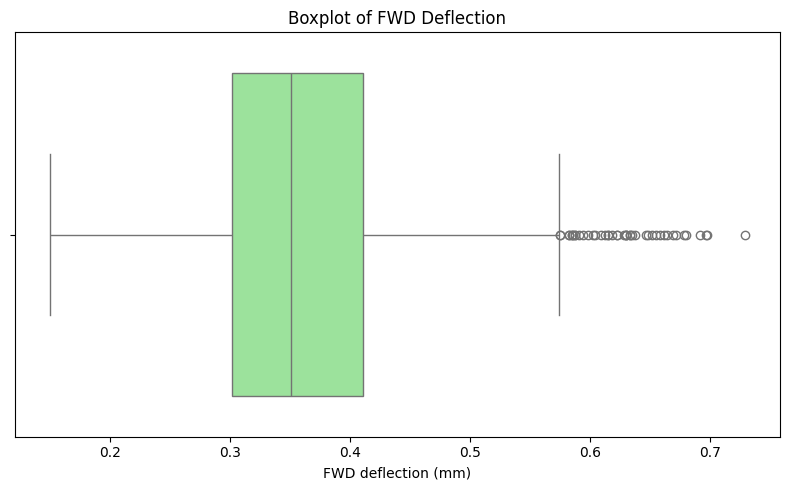

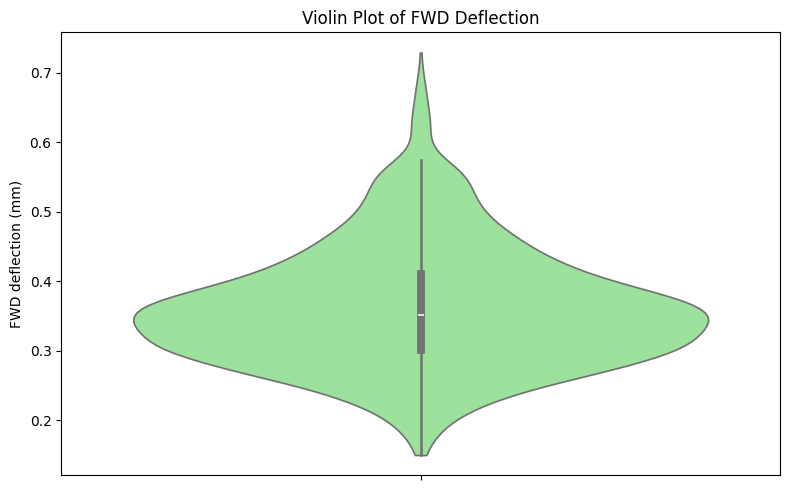

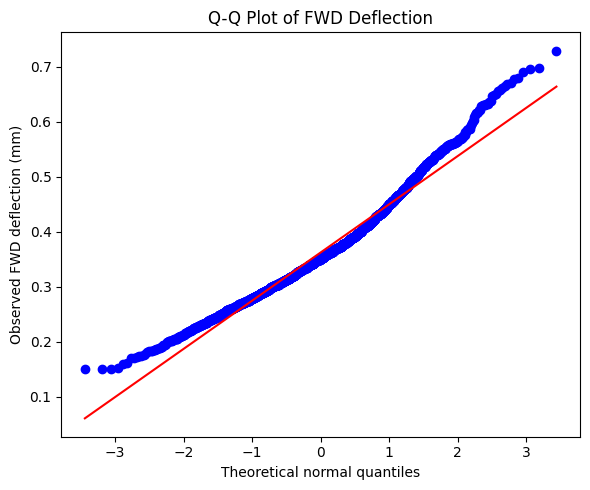

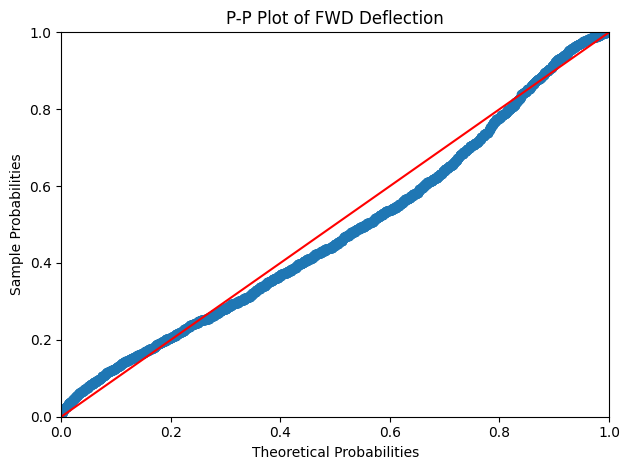

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.graphics.gofplots import ProbPlot

df = pd.read_csv("pavement_transportation_master_dataset.csv")
print(df.head())
print("\nData type:", df['FWD_deflection_mm'].dtype)
print("Missing values:", df['FWD_deflection_mm'].isna().sum())

x = df['FWD_deflection_mm'].dropna()

print("\nDescriptive statistics:")
print(x.describe())

#Identify outliers using the IQR rule
Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_outliers = df[(df['FWD_deflection_mm'] < lower_bound) |
                 (df['FWD_deflection_mm'] > upper_bound)]

print("\nQ1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Lower outliers:", (x < lower_bound).sum())
print("Upper outliers:", (x > upper_bound).sum())
print("Total outliers:", len(df_outliers))
print("Outliers (%):", len(df_outliers) / len(x) * 100)
print("\nOutlier observations:")
print(df_outliers[['section_id', 'survey_year', 'FWD_deflection_mm']])

# Keep outliers in all four plots.

# 1. Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=x, color='lightgreen', whis=1.5)
plt.title("Boxplot of FWD Deflection")
plt.xlabel("FWD deflection (mm)")
plt.tight_layout()
plt.savefig("FWD_boxplot.png", dpi=300)
plt.show()

# 2. Violin plot
plt.figure(figsize=(8, 5))
sns.violinplot(y=x, color='lightgreen', inner='box', cut=0)
plt.title("Violin Plot of FWD Deflection")
plt.ylabel("FWD deflection (mm)")
plt.tight_layout()
plt.savefig("FWD_violin.png", dpi=300)
plt.show()

# 3. Q-Q plot
plt.figure(figsize=(6, 5))
stats.probplot(x, dist="norm", plot=plt)
plt.title("Q-Q Plot of FWD Deflection")
plt.xlabel("Theoretical normal quantiles")
plt.ylabel("Observed FWD deflection (mm)")
plt.tight_layout()
plt.savefig("FWD_qq.png", dpi=300)
plt.show()

# 4. P-P plot
ProbPlot(x, fit=True).ppplot(line='45')
plt.title("P-P Plot of FWD Deflection")
plt.tight_layout()
plt.savefig("FWD_pp.png", dpi=300)
plt.show()
